# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움
- 멀티 에이전트는 작업을 역할별로 나누고, 각 결과를 다음 담장자에게 전달
    - Network: 동료 간 상호 위임이 가능한 연결 구조
    - Supervisor: 여러 담장자의 순서를 결정하는 중앙 관리자
    - Hierarchical: 팀 안에 팀이 있는 계층적 조직

### HandOff
- 현재 담장자가 다른 담장자에게 실행 제어권을 넘기는 것

In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [ ]:
# total=False: 안에 데이터가 처음부터 다 채워질 필요는 없음
class HandoffState(TypedDict, total=False):
    request: str       # 사용자가 입력한 요청
    department: str    # 요청을 처리할 담당
    answer: str        # 담당이 작성한 답변


# 사용자 요청을 보고 담당을 정하는 함수
def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

def route_handoff(state: HandoffState):
    return state['department']

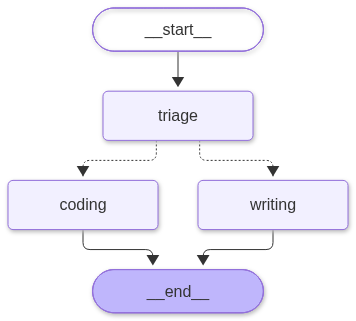

In [5]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)
handoff_graph = builder.compile()

handoff_graph

In [6]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [ ]:
# stream(): 실행되는 중간 결과를 차례대로 받음
# stream_mode="updates": 각 노드가 반환한 변경 내용만 확인
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


위에는 기본 구조??

In [8]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [9]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# 1. 분류 에이전트
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]: # Literal로 묶어서 에이전트끼리 대화 가능
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"

    # updates: 공유 상태(State)에 department값을 저장. got: 다음에 실행할 노드를 지정
    return Command(update={"department": dept}, goto = dept) # goto해서 에이전트끼리 대화 가능

# 2. 코딩 에이전트
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}


# 3. 글쓰기 에이전트
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요.\n요청: {state['request']}"
    )
    return {"answer": response.content}

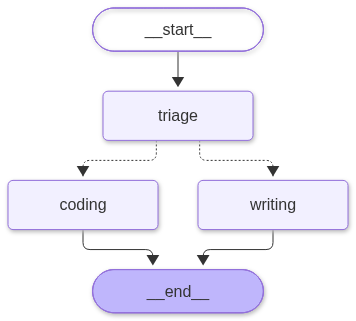

In [10]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)

graph = builder.compile()
graph


In [11]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")
    print(f"담당: {result["department"]}")
    print(f"답변: {result["answer"]}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for`문은 **여러 개의 데이터를 하나씩 꺼내서 반복 작업할 때** 사용합니다.

## 1. 기본 형태

```python
for 변수 in 반복할_데이터:
    실행할_문장
```

예를 들어 리스트의 과일을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

`for`문은 리스트에서 값을 하나씩 꺼내 `fruit` 변수에 저장한 뒤, `print(fruit)`를 실행합니다.

---

## 2. 숫자를 반복할 때: `range()`

`range()`는 일정한 범위의 숫자를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

주의할 점은 `range(5)`가 **0부터 4까지**라는 것입니다. 마지막 숫자 `5`는 포함되지 않습니다.

### 1부터 5까지 출력하기

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

형식은 다음과 같습니다.

```python
range(시작값, 끝값)
```

끝값은 포함되지 않습니다.

---

## 3. 반복하면서 계산하기

```python
total = 0

for number in [1, 2, 3, 4, 5]:
    total = total + number

print(total)
```

결과:

```text
15
```

리스트의 숫자를 하나씩 꺼내 `total`에 더한 예제입니다.

---

## 4. 문자열도 반복할 수 있습니다

문자열은 글자 하나씩 꺼낼 수 있습니다.

```python
for letter in "Python":
    print(letter)

### 1. Network
각 전문 에이전트로 되어 있으면 직접 이웃 에이전트로 handoff를 함

In [12]:
import matplotlib.pyplot as plt
import os, json
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field

In [13]:
load_dotenv()

True

In [14]:
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(".env에 openai api key 설정!")

llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [15]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [ ]:
def ask(system: str, user: str) -> str:
    """시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다."""
    # system: 역할과 지시
    # human: 실제로 처리할 입력
    response = llm.invoke([("system", system), ("human", user)])
    return str(response.content)

In [ ]:
# 조사 에이전트와 차트 에이전트가 공유할 상태
class ChartState(TypedDict, total=False):
    question: str
    source: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str


# 차트에 들어갈 데이터 하나의 구조
class ChartData(TypedDict):
    label: str
    value: float

In [ ]:
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError("TAVILY KEY ERROR!")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)

    # 검색 결과에서 제목, 주소, 본문만 꺼냄
    # get(): 키가 없으면 지정한 기본값을 사용
    # [:1500]: 본문은 앞에서 1500자까지만 사용
    return [{"title": x.get("title", ""), "url": x.get("url", ""), "content": x.get("content", "")[:1500]} for x in result.get("results", [])]

In [ ]:
# LLM이 반환해야 하는 응답 구조
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만")
    summary: str

In [ ]:
# 자유로운 문장 대신 ResearchData 구조에 맞춰 응답하게 함
research_llm = llm.with_structured_output(ResearchData)

In [ ]:
# 조사 에이전트
# 조사 성공이면 chart, 수치가 없으면 종료
def researcher(state: ChartState) -> Command[Literal["chart", "__end__"]]:
    sources = search_web(state['question'])
    parsed = research_llm.invoke([
        ("system", "검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요"),
        
        # 딕셔너리를 JSON 문자열로 바꿔서 전달
        # ensure_ascii=False: 한글을 그대로 표시
        ("human", json.dumps({"question": state["question"], "sources": sources},
                            ensure_ascii=False))
    ])

    # 빈 리스트면 False로 판단
    # 확인된 수치가 없으면 차트를 만들지 않고 종료
    if not parsed.data:
        return Command(update={"sources": sources, "error": "검증 가능한 수치가 없습니다."}, goto = END)

    return Command(update={"sources":sources, "data":[x.model_dump() if hasattr(x, "model_dump") else x for x in parsed.data], "summary": parsed.summary}, goto="chart")


In [22]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)

    # 내가 추가
    # 한글 깨짐 방지
    plt.rcParams["font.family"] = "Malgun Gothic"
    # 마이너스(-) 기호 깨짐 방지
    plt.rcParams["axes.unicode_minus"] = False
    
    return Command(update={"chart_path":str(path)}, goto=END)

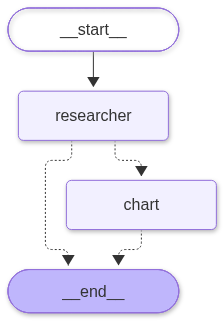

In [23]:
builder = StateGraph(ChartState)
builder.add_node("researcher", researcher)
builder.add_node("chart", chart)
builder.add_edge(START, "researcher")
network_chart = builder.compile() # END를 goto=END로 해뒀기 때문에 필요없음
network_chart

C:\Users\이희승\AppData\Local\Temp\ipykernel_44452\949589031.py:7: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\이희승\AppData\Local\Temp\ipykernel_44452\949589031.py:9: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=140)
c:\VSGit\14_Agent\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


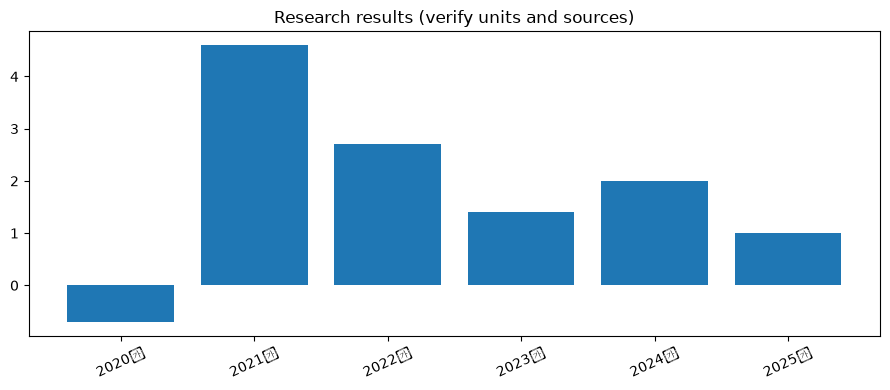

In [24]:
result = network_chart.invoke({"question": "2020년부터 2025까지 한국의 연도별 실질 GDP 성장률(%)"}, config={"recursion_limit": 5})

### 멀티 에이전트 기반(네트워크) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석하여 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템을 개발

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 전달받아 취약 영역에 대한 객관식 문제를 생성

예시
```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}
1. 학생의 학습 점수를 입력 받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. LLM을 이용하여 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. LLM을 이용해 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```

In [ ]:
# 강사님
# 진단 에이전트와 문제 출제 에이전트가 공유하는 상태
class StudyState(TypedDict, total=False):
    scores: dict[str, int]
    weakness: str
    diagnosis: str
    quiz: str

def diagnosis(state: StudyState) -> Command[Literal["quiz"]]:
    scores = state["scores"]
    if not scores or any(not 0 <= v <= 100 for v in scores.values()):
        raise ValueError("영역별 점수를 0 ~ 100 사이로 입력하세요.")
    
    # 딕셔너리를 순회하면 키가 나옴
    # key=scores.get: 각 키에 해당하는 점수를 기준으로 비교
    # 가장 낮은 점수를 가진 영역 이름을 반환
    weak = min(scores, key=scores.get)
    explanation = ask("당신은 친절한 학습 진단 전문가입니다. 점수의 의미를 과장하지 말고 3문장으로 분석하세요.", f"영역별 점수: {scores}, 최저 영역: {weak}")
    
    # 취약 영역과 진단 결과를 저장하고 문제 출제 담당에게 전달
    return Command(update={"weakness": weak, "diagnosis": explanation}, goto="quiz")

def quiz(state: StudyState) -> Command[Literal["__end__"]]:
    content = ask("당신은 학습문제 출제 전문가입니다. 지정된 취약 영역에 대해 객관식 3문제를 만들고 각 문항에 정답과 쉬운 해설을 붙이세요. 애매한 문항은 피하세요.", f"취약 영역: {state['weakness']}\n진단: {state['diagnosis']}")
    return Command(update={"quiz": content}, goto=END)


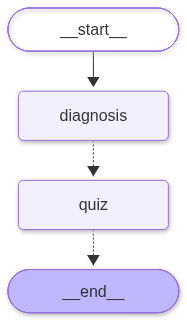

In [ ]:
builder = StateGraph(StudyState)
builder.add_node("diagnosis", diagnosis)
builder.add_node("quiz", quiz)
builder.add_edge(START, "diagnosis")

# 진단 후 문제 출제, 문제 출제 후 종료는 Command가 처리
study_network = builder.compile()
study_network

In [27]:
result = study_network.invoke({"scores": {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}}, config = {"recursion_limit": 5})

In [ ]:
print("[진단]", result["diagnosis"], "\n[문제]", result["quiz"])

[진단] 파이썬 기초문법은 90점으로 매우 탄탄하고, 데이터 분석은 75점으로 기본기가 형성되어 있습니다.  
딥러닝은 60점으로 다른 영역보다 낮아 핵심 개념과 실습을 보완할 필요가 있습니다.  
다만 점수만으로 실력을 단정하기보다는, 딥러닝의 세부 오답 유형을 확인한 뒤 기초 이론과 간단한 모델 구현부터 단계적으로 학습하는 것이 좋습니다. 
[문제] ## 딥러닝 객관식 문제 3문항

### 1번. 활성화 함수 계산

다음 신경망의 입력값과 가중치가 주어졌습니다.

- 입력 \(x = [2, 1]\)
- 가중치 \(w = [3, -1]\)
- 편향 \(b = 0\)
- 활성화 함수: ReLU

이때 신경망의 최종 출력값은 얼마인가요?

① -1  
② 0  
③ 5  
④ 6  

**정답: ③ 5**

**해설:**  
먼저 가중합을 계산합니다.

\[
2 \times 3 + 1 \times (-1) + 0 = 5
\]

ReLU 함수는 입력이 양수이면 그대로 출력하므로 결과는 **5**입니다.

\[
\text{ReLU}(5) = 5
\]

---

### 2번. 학습 데이터와 검증 데이터

딥러닝 모델을 학습할 때 검증 데이터(validation data)를 사용하는 주된 목적은 무엇인가요?

① 모델의 가중치를 직접 계산하기 위해  
② 학습 중 모델의 성능을 확인하고 과적합을 감지하기 위해  
③ 입력 데이터의 개수를 늘리기 위해  
④ 파이썬 문법 오류를 찾기 위해  

**정답: ② 학습 중 모델의 성능을 확인하고 과적합을 감지하기 위해**

**해설:**  
학습 데이터는 모델의 가중치를 조정하는 데 사용합니다.  
검증 데이터는 학습에 직접 사용하지 않고, 학습 중 모델이 새로운 데이터에도 잘 작동하는지 확인하는 데 사용합니다.

학습 데이터 성능은 계속 좋아지지만 검증 데이터 성능이 나빠진다면 **과적합**일 가능성이 있습니다.

---

### 3번. 과적합 상황 판단

어떤 딥러닝 모델의 학습 결과가 다음과 같습니다.

- 학습 데이터 

In [29]:
# 내가 한 거
class StudentState(TypedDict, total=False):
    question: str  # 지워도 될 듯
    scores: dict[str, int]
    min_sub: str
    min_score: int
    summary: str
    quiz: list[dict]

# state는 자료형
def check_score(state: StudentState):
    scores = state["scores"]

    for score in scores.values():
        if score>100 or score<0:
            raise RuntimeError("점수가 0~100까지의 범위가 아님")


def find_min_socore(state: StudentState):
    scores = state["scores"]
    score_key, score_value = min(scores.items(), key=lambda x: x[1])
    
    
    return {"min_sub": score_key, "min_score": score_value}

class ResearchScore(BaseModel):
    summary: str = Field(description="학생의 학습 상태를 3문장으로 진단")


def diagnose_student(state: StudentState):
    scores = state["scores"]
    min_sub = state["min_sub"]
    min_score = state["min_score"]

    research_score_llm = llm.with_structured_output(ResearchScore)

    response = research_score_llm.invoke([
        ("system", "학생의 학습 상태를 정확히 3문장으로 진단해"),
        ("human", f"학생 점수: {scores}, 취약 과목: {min_sub}, 최저 점수: {min_score}")
    ])

    # 진단 결과를 StudentState에 저장
    return {"summary": response.summary}


# 객관식 문제 하나의 데이터 구조
class QuizData(BaseModel):
    question: str = Field(description="객관식 문제")
    options: list[str] = Field(description="4개의 선택지", min_length=4, max_length=4)
    answer: str = Field(description="정답 선택지")
    explanation: str = Field(description="정답에 대한 해설")


# 객관식 문제 3개의 데이터 구조
class QuizResult(BaseModel):
    quiz: list[QuizData] = Field(description="객관식 문제 3개", min_length=3, max_length=3)


# 문제 출제 에이전트
def create_quiz(state: StudentState):
    min_sub = state["min_sub"]
    summary = state["summary"]

    quiz_llm = llm.with_structured_output(QuizResult)

    response = quiz_llm.invoke([
        ("system", "학생의 취약 영역에 대한 객관식 문제를 정확히 3개 출제하세요. 각 문제는 4개의 선택지, 정답, 해설을 포함해야 합니다. 정답은 반드시 선택지 중 하나여야 합니다."),
        ("human", f"취약 과목: {min_sub}, 학습 진단: {summary}")
    ])

    # 생성된 문제를 딕셔너리 리스트로 변환
    return {"quiz": [q.model_dump() for q in response.quiz]}


# LangGraph 구성
builder = StateGraph(StudentState)
builder.add_node("check_score", check_score)
builder.add_node("find_min_score", find_min_socore)
builder.add_node("diagnose_student", diagnose_student)
builder.add_node("create_quiz", create_quiz)

builder.add_edge(START, "check_score")
builder.add_edge("check_score", "find_min_score")
builder.add_edge("find_min_score", "diagnose_student")
builder.add_edge("diagnose_student", "create_quiz")
builder.add_edge("create_quiz", END)

student_agent = builder.compile()


# 실행
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

result = student_agent.invoke({"scores": scores})

print("취약 과목:", result["min_sub"])
print("최저 점수:", result["min_score"])
print("학습 진단:", result["summary"])

for i, quiz in enumerate(result["quiz"], 1):
    print(f"\n문제 {i}. {quiz['question']}")
    for j, option in enumerate(quiz["options"], 1):
        print(f"{j}. {option}")
    print("정답:", quiz["answer"])
    print("해설:", quiz["explanation"])


취약 과목: 딥러닝
최저 점수: 60
학습 진단: 학생은 파이썬 기초문법에서 90점으로 높은 숙련도를 보이고 있습니다. 데이터 분석은 75점으로 기본 개념을 이해하고 있으나 추가적인 연습이 필요합니다. 딥러닝은 60점으로 가장 취약하므로 핵심 개념 복습과 실습 중심의 학습을 우선적으로 진행해야 합니다.

문제 1. 딥러닝에서 ReLU(Rectified Linear Unit) 활성화 함수의 수식으로 옳은 것은 무엇인가요?
1. f(x) = x²
2. f(x) = max(0, x)
3. f(x) = 1 / (1 + e⁻ˣ)
4. f(x) = tanh(x)
정답: f(x) = max(0, x)
해설: ReLU 함수는 입력값 x가 0보다 크면 x를 그대로 출력하고, 0 이하이면 0을 출력합니다. 계산이 간단하고 깊은 신경망에서 기울기 소실 문제를 줄이는 데 도움이 됩니다.

문제 2. 신경망 학습에서 역전파(backpropagation)의 주요 목적은 무엇인가요?
1. 입력 데이터를 무작위로 섞는 것
2. 손실 함수의 기울기를 계산하여 가중치를 업데이트하는 것
3. 학습 데이터를 새로운 데이터로 변환하는 것
4. 출력층의 뉴런 개수를 자동으로 늘리는 것
정답: 손실 함수의 기울기를 계산하여 가중치를 업데이트하는 것
해설: 역전파는 출력에서 계산된 손실을 각 가중치에 대해 미분하여 기울기를 구하는 과정입니다. 이후 경사 하강법 등을 사용해 손실이 감소하도록 가중치를 수정합니다.

문제 3. 딥러닝 모델이 훈련 데이터에서는 높은 정확도를 보이지만 검증 데이터에서는 낮은 정확도를 보일 때 가장 적절한 설명은 무엇인가요?
1. 과소적합이며 모델의 복잡도를 높여야 한다
2. 과적합이며 정규화나 드롭아웃 등을 사용할 수 있다
3. 활성화 함수가 항상 선형이기 때문이다
4. 학습률이 반드시 0이어야 하기 때문이다
정답: 과적합이며 정규화나 드롭아웃 등을 사용할 수 있다
해설: 훈련 데이터에 지나치게 맞춰져 새로운 데이터에 대한 일반화 성능이 낮아지는 현상을 과적합이라고 합니다. 

늦게 옴

### 2. Supervisor(슈퍼바이저)
Supervisor가 여러 전문 에이전트에게 작업을 순서대로 맡기고, 모든 작업이 끝나면 결과를 반환하는 구조

In [ ]:
# total=False: 안에 데이터가 다 채워질 필요는 없다
class TripState(TypedDict, total=False):
    request: str                # 사용자의 여행 요청
    sources: list[dict]         # 웹 검색 결과
    research: str               # 조사 에이전트가 작성한 요약 
    recommendation: str         # 추천 에이전트가 작성한 결과
    saved_path: str             # 저장된 파일 경로
    next_step: str              # LLM이 선택한 다음 작업
    error: str                  # 오류 정보를 기록하기 위한 필드

# 다음 작업으로 선택할 수 있는 값들을 제한
class RouteDecision(BaseModel):
    next_step: Literal["search_agent", "recommend_agent", "save_agent", "FINISH"] # 에이전트가 어디로 이동할지, 이런 에이전트가 존재한다

In [31]:
router_llm = llm.with_structured_output(RouteDecision)

In [ ]:
# 감독자: 현재 상태를 확인하고 다음 담당에게 작업을 전달
def supervisor(state: TripState) -> Command[Literal["search_agent", "recommend_agent", "save_agent", "__end__"]]:
    # 각 결과가 있으면 True, 없거나 비어 있으면 False
    completed = {"search_agent":bool(state.get("research")), "recommend_agent":bool(state.get("recommendation")), "save_agent":bool(state.get("saved_path"))}

    # all(): 모든 값이 True일 때 True
    # 검색, 추천, 저장이 전부 끝났으면 종료
    if all(completed.values()): # all()은 반복 가능한(iterable) 자료형(리스트, 튜플, 딕셔너리, 집합 등)의 모든 요소가 참(True)인지 확인
        return Command(goto=END)

    decision = router_llm.invoke([
        ("system", "당신은 여행 작업 감독자입니다. 반드시 검색, 추천, 저장 순서로 진행하세요. 이미 완료한 작업은 반복하지 마세요. 다음 작업 이름만 선택하세요. "),
        ("human", json.dumps({"request": state["request"], "completed": completed}, ensure_ascii=False))
    ])


    # 아직 완료하지 않은 첫 번째 작업 이름을 꺼냄
    # 딕셔너리에 넣은 순서대로 검색 → 추천 → 저장
    expected = next(k for k, v in completed.items() if not v)

    # LLM의 선택은 next_step에 기록
    # 실제 이동은 decision.next_step이 아니라 expected로 함
    return Command(update={"next_step": decision.next_step}, goto=expected)

- 이터러블: 데이터가 모여있는 구조, 순서를 보장하지 않고 인덱싱을 꼭 보장하지 않음
- 이터레이터:
- iter(): 이터러블에 이 함수를 사용하면 순서를 가지면서 차례대로 나열할 수 있게 됨 -> next()를 사용할 수 있게 됨
- 리스트도 이터러블 객체. 이터레이터는 아님

```
li = [10, 20, 30, 40]
next(li) # 에러
next(iter(li)) # 출력됨
```

In [33]:
def trip_search(state: TripState) -> Command[Literal["supervisor"]]:
    sources = search_web(state["request"] + " 여행 추천 관광지 날씨 예보")
    text = ask("여행 조사원입니다. 출처에 근거한 내용만 요약하고 날짜가 확인되지 않은 날씨는 확정하지 마세요.", json.dumps(sources, ensure_ascii=False))
    return Command(update={"sources": sources, "research": text}, goto="supervisor")

def trip_recommend(state: TripState) -> Command[Literal["supervisor"]]:
    text = ask("여행 추천 전문가입니다. 조사 내용을 바탕으로 여행지 3곳과 이유, 날씨 확인 주의사항을 작성하세요. 검증되지 않은 운영시간, 예보는 쓰지 마세요.", state["request"]+"\n"+state["research"])
    return Command(update={"recommendation": text}, goto="supervisor")

def trip_save(state: TripState) -> Command[Literal["supervisor"]]:
    path = OUTPUT_DIR / "trip_recommendation.md"
    refs = "\n".join("- "+s["url"] for s in state.get("sources", []))
    path.write_text("# 여행 추천\n\n"+state["recommendation"] + "\n\n### 참고 검색 링크\n"+refs, encoding="utf-8")
    return Command(update={"saved_path": str(path)}, goto="supervisor")

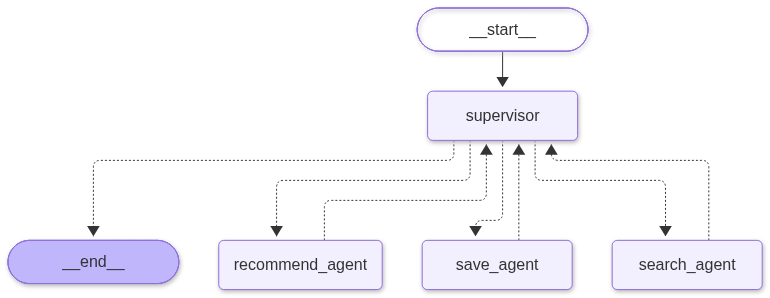

In [34]:
builder = StateGraph(TripState)
for name, fn in [("supervisor", supervisor), ("search_agent", trip_search), ("recommend_agent", trip_recommend), ("save_agent", trip_save)]:
    builder.add_node(name, fn)
builder.add_edge(START, "supervisor")
trip_graph = builder.compile()
trip_graph

In [35]:
result = trip_graph.invoke({"request": "제주도 2박 3일 자연 경관 중심 여행지를 추천해줘"}, config={"recursion_limit": 10})
result

{'request': '제주도 2박 3일 자연 경관 중심 여행지를 추천해줘',
 'sources': [{'title': '제주도 2박3일 여행 계획 중인데 자연경관과 맛집 투어를 함께 둘러 볼 수 있는 코스 추천해 주세요. | 궁금할 땐, 아하!',
   'url': 'https://www.a-ha.io/questions/4da2efd681b7fedbaab65b1255889acc',
   'content': '답변드립니당\n\n  질문자님, 제주도 2박3일 여행 코스로 첫째 날 성산일출봉과 섭지코지, 월정리 해변을 즐기고 월정리 인근 감성 카페와 갈치조림 맛집을 방문하시면 좋습니다. 둘째 날은 한라산 둘레길 산책 후 오설록 티 뮤지엄에서 녹차 디저트와 협재 해변, 천제연 폭포 등 남서부 명소와 현지 인기 흑돼지구이 맛집을 추천드립니다. 마지막 날은 우도에서 땅콩 아이스크림을 맛보고, 동문시장 또는 애월카페 지역에서 특산품과 분위기 좋은 대형 카페 체험을 권장합니다. 제주 서부 카멜리아힐과 애월 해안도로도 일몰 명소로 효율적 동선에 포함하면 자연경관과 맛집, 카페 투어를 모두 만족할 수 있습니다. 일정 내내 차량 이동이 편리하니 렌터카 권장하며 추천 코스와 맛집, 카페는 현지 인기와 풍광 모두 확실하게 고려한 구성입니다. [...] 아하\n\n 전문가 신청\n\n여행\n\n## 제주도\n\n탈퇴한 사용자\n\n탈퇴한 사용자\n\n# 제주도 2박3일 여행 계획 중인데 자연경관과 맛집 투어를 함께 둘러 볼 수 있는 코스 추천해 주세요.\n\n제주도 2박 3일 여행을 계획 중인데 자연 경관을 충분히 즐기면서도 유명 맛집과 분위기 좋은 카페를 함께 방문할 수 있는 효율적인 여행 코스가 궁금합니다.\n\n2개의 답변이 있어요!\n\n 동바오동동\n\n  동바오동동\n\n  제주도 2박3일을 렌트를 하신다고 한다면 하루는 우도에 들어가셔서 전기차를 타고 섬을 한번 돌면 좋습니다 거기서 어느 음식점이던 맛이 있는데 해물라면 짬뽕이나 짜장면을 드시는게 좋구요 해변에서 사진도 

In [36]:
print(result["recommendation"])
print("저장 파일: ", result["saved_path"])

제주 **2박 3일 자연경관 중심 여행**이라면, 동부–중문–공항 인근 순서로 이동하는 구성이 무난합니다. 아래는 자연 풍경이 뚜렷하고 일정에 넣기 좋은 **핵심 여행지 3곳**입니다.

## 추천 여행지 3곳

### 1. 성산일출봉·섭지코지
- 제주 동부를 대표하는 화산 지형과 해안 풍경을 함께 볼 수 있습니다.
- 성산일출봉은 전망이 뛰어나고, 섭지코지는 해안 산책과 바다 조망에 적합합니다.
- 두 장소를 같은 날 묶기 좋아 첫날 코스로 추천합니다.

### 2. 중문 주상절리·천제연폭포 일대
- 주상절리에서는 수직으로 발달한 해안 절벽을, 천제연폭포에서는 숲과 계곡 경관을 감상할 수 있습니다.
- 해안 풍경과 내륙의 녹음이 함께 있어 제주 자연경관을 다양하게 볼 수 있습니다.
- 일정이 빠듯하면 주상절리와 천제연폭포 중 한 곳을 선택하세요.

### 3. 협재·금능 해변 또는 애월 해안
- 협재·금능은 맑은 바다와 비양도 조망이 장점이고, 애월은 해안도로를 따라 바다 풍경을 감상하기 좋습니다.
- 귀국 전 제주시와 공항 방향으로 이동하기 비교적 편한 서부권 일정입니다.
- 해수욕보다는 해안 산책과 경관 감상 중심으로 계획하는 것이 좋습니다.

## 2박 3일 일정 예시

### 1일차｜동부 해안
**제주공항 → 성산일출봉 → 섭지코지 → 성산 숙박**

- 공항 도착 시간이 늦으면 성산일출봉과 섭지코지 중 한 곳만 선택합니다.
- 해산물이나 갈치조림은 성산 일대에서 식사 선택지로 고려할 수 있습니다.

### 2일차｜중문·서귀포 자연경관
**성산 → 중문 주상절리 → 천제연폭포 또는 서귀포 해안 → 중문·서귀포 숙박**

- 두 장소를 모두 방문하면 산책 시간이 길어질 수 있으므로 체력과 날씨에 따라 조정합니다.
- 해안 절벽과 폭포를 모두 보고 싶다면 이날을 자연경관 중심으로 여유 있게 배정하는 편이 좋습니다.

### 3일차｜서부 해안
**숙소 → 협재·금능 또는 애월 해안 → 제주공항**

- 항공편이 이르면 서부 해안을 생략하고 공항 인근 산책지

### 3. Hierarchical
- 팀 내부에 여러 작업 노드를 두고, 각 팀을 독립적인 Subgraph(하위 그래프)로 구성하는 방식
- 계층형 멀티 에이전트

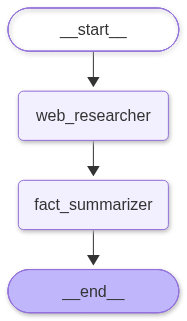

In [37]:
class ResearchTeamState(TypedDict, total=False):
    topic: str                  # 조사할 주제
    sources: list[dict]         # 웹 검색 결과
    notes: str                  # 검색 결과를 요약한 조사 노트

def find_sources(s: ResearchTeamState):
    return {"sources": search_web(s['topic'])}

def summarize_sources(s: ResearchTeamState):
    return {"notes": ask("당신은 조사 전문가입니다. 제공된 검색 결과만 바탕으로 핵심 사실을 요약하고 불확실한 부분은 표시하세요.", json.dumps(s["sources"], ensure_ascii=False))}

research_builder = StateGraph(ResearchTeamState)
research_builder.add_node("web_researcher", find_sources)
research_builder.add_node("fact_summarizer", summarize_sources)
research_builder.add_edge(START, "web_researcher")
research_builder.add_edge("web_researcher", "fact_summarizer")
research_builder.add_edge("fact_summarizer", END)
research_team = research_builder.compile()
research_team

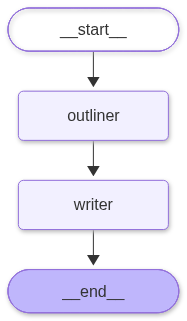

In [38]:
# 문서 기뢱자
class WritingTeamState(TypedDict, total=False):
    topic: str          # 보고서 주제
    notes: str          # 조사팀에서 작성한 조사 노트
    outline: str        # 보고서 목차 및 개요
    report: str         # 최종 보고서

def outline_writer(s: WritingTeamState):
    return {"outline": ask("당신은 문서 기뢱자입니다. 조사 노트만을 활용하여 제목과 3~4개 소제목으로 개요를 만드세요.", s["topic"]+"\n"+s["notes"])}

def report_writer(s: WritingTeamState):
    return {"report": ask("당신은 보고서 작성 전문가입니다. 개요와 조사 노트만을 사용하여 한국어 마크다운 보고서를 작성하세요. 불확실한 정보는 불확실하다고 표시하세요.", json.dumps(s, ensure_ascii=False))}

writing_builder = StateGraph(WritingTeamState)
writing_builder.add_node("outliner", outline_writer)
writing_builder.add_node("writer", report_writer)
writing_builder.add_edge(START, "outliner")
writing_builder.add_edge("outliner", "writer")
writing_builder.add_edge("writer", END)
writing_team = writing_builder.compile()
writing_team

In [39]:
class TopState(TypedDict, total=False):
    topic: str                  
    notes: str
    sources: list[dict]
    outline: str
    report: str
    saved_path: str

class TeamChoice(BaseModel):
    team: Literal["research_team", "writing_team", "FINISH"]

top_router = llm.with_structured_output(TeamChoice)

def top_supervisor(s: TopState) -> Command[Literal["research_team", "writing_team", "__end__"]]:
    if s.get("report"):
        return Command(goto=END)
    choice = top_router.invoke([
        ("system", "상위 감독자입니다. 조사 노트가 없으면 research_team, 조사 노트가 있고 보고서가 없으면 writing_team을 선택하세요."),
        ("human", json.dumps({"topic": s["topic"], "has_notes": bool(s.get("notes")), "has_report": bool(s.get("report"))}, ensure_ascii=False))
    ])
    # 길을 잃었을 떄
    expected = "writing_team" if s.get("notes") else "research_team"
    return Command(goto=expected)

def run_research(s: TopState) -> Command[Literal["top_supervisor"]]:
    out = research_team.invoke({"topic": s["topic"]}, config={"recursion_limit": 10})
    return Command(update={"notes": out['notes'], "sources": out["sources"]}, goto="top_supervisor")

def run_writing(s: TopState) -> Command[Literal["top_supervisor"]]:
    out = writing_team.invoke({"topic": s["topic"], "notes": s["notes"]}, config={"recursion_limit": 10})
    path = OUTPUT_DIR / "agent_report.md"
    refs = "\n".join("- " + x['url'] for x in s["sources"])
    path.write_text(out['report'] + "\n\n### 검색 출처\n" + refs, encoding='utf-8')
    return Command(update={"outline": out['outline'], "report": out["report"], "saved_path": str(path)}, goto="top_supervisor")

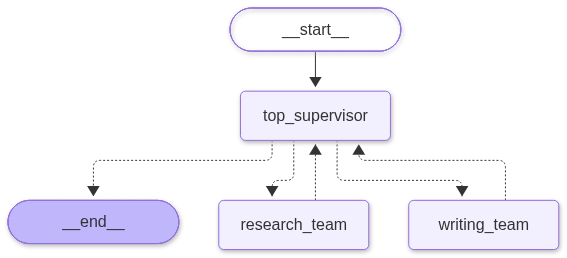

In [40]:
top_builder = StateGraph(TopState)
top_builder.add_node("top_supervisor", top_supervisor)
top_builder.add_node("research_team", run_research)
top_builder.add_node("writing_team", run_writing)
top_builder.add_edge(START, "top_supervisor")
hierarchical_graph = top_builder.compile()
hierarchical_graph

In [41]:
result = hierarchical_graph.invoke({"topic": "멀티 에이전트 시스템의 개념과 실제 활용 사례"}, config={"recursion_limit": 10})
print(result["report"])

# 멀티 에이전트 시스템의 개념과 실제 활용 사례

## 1. 개요

멀티 에이전트 시스템(Multi-Agent System, MAS 또는 Multi-Agent Collaboration, MAC)은 여러 자율 AI 에이전트가 정보를 공유하고 업무를 분담·조정하여, 단일 에이전트만으로 처리하기 어려운 복잡한 문제를 해결하는 구조다.

각 에이전트는 데이터 검색, 예측, 분석, 작성, 가격 조정, 물류 등 특정 업무에 특화될 수 있다. 시스템은 이들 에이전트가 공동 목표를 달성하도록 작업을 배정하고, 결과를 통합하며, 필요에 따라 작업 순서와 의사결정을 조정한다.

다만 멀티 에이전트 구조를 도입한다고 해서 모든 환경에서 자동으로 성능이 향상되는 것은 아니다. 실제 효과는 오케스트레이션, 결과 검증, 권한 관리, 보안 설계 등에 따라 달라질 수 있다.

---

## 2. 다중 에이전트 시스템의 개념과 구성

### 2.1 전문 에이전트

전문 에이전트는 전체 업무 중 특정 기능을 담당한다. 주요 역할은 다음과 같다.

- 데이터 검색
- 수요 또는 질병 예측
- 시장·위험 분석
- 문서 및 콘텐츠 작성
- 가격 조정
- 재고 및 재주문 수준 관리
- 물류 운영
- 코드 분석 및 리뷰
- 장비 상태 감사와 수리 일정 조정

이와 같은 역할 분담을 통해 각 에이전트는 특정 업무에 집중하고, 전체 시스템은 여러 전문 기능을 결합해 복합적인 문제를 처리한다.

### 2.2 슈퍼바이저와 오케스트레이터

슈퍼바이저 또는 오케스트레이터는 사용자의 복잡한 요청을 여러 하위 작업으로 분해한다. 이후 각 작업을 적절한 전문 에이전트에 배정하고, 에이전트의 결과를 통합한다.

예를 들어 ‘소매 예측 최적화’와 같은 요청이 들어오면 다음과 같은 작업으로 나눌 수 있다.

1. 관련 데이터 검색
2. 적절한 예측 모델 선택
3. 예측 결과 생성
4. 결과 통합 및 해석

이 과정에서 오케스트레이터는 각 에이전트의 작업 순서와 결과를 조정하는 역할을 한다.

### 2.3 통신·조정 

# **2. 종합 문제**
### AI 소프트웨어 개발팀 구축
- Hierachical 멀티 에이전트 구조로 직접 설계하고 구현
- AI 기반 소프트웨어 개발 자동화 서비스를 만드는 개발자
```
    학생 성적 관리 프로그램을 만들어줘. 학생 이름과 점수를 등록할 수 있고, 전체 학생 목록 조회, 평균 점수 계산, 최고 점수 학생 조회 기능이 필요해
```
- 기존의 단일 LLM 시스템은 이 요청을 받아 한 번엔 코드를 생성(이렇게 하지 말고) 
    - 기획팀: 사용자 요구사항을 분석하고 프로그램의 구조를 설계
    - 개발팀: 설계서를 바탕으로 Python 코드를 작성하고 품질을 검토
    - 상위 감독자: 기획팀과 개발팀의 작업 순서를 관리하고 최종 결과물을 완성

### 요구 사항
1. Top Supervisor
- 전체 프로젝트 진행을 관리하는 상위 감독자를 구현
- 현재 State를 확인하고 아래 규칙에 따라 작업을 배정
    - 설계서가 없다면 planning_team 실행
    - 설계서가 있고, 코드가 없다면 development_team 실행
    - 코드가 있고, 검토를 통과했다면 END
    - 코드 검토에 실패했다면 개발팀에 수정 요청

2. Planning Team
- 기획팀 작업 순서 결정 노드
- 사용자 요구사항 분석 노드
- 함수, 자료구조, 프로그램 구조 설계 노드
- 기획팀의 최종 출력에는 아래 내용이 포함되어야 함
    - 프로젝트 목적
    - 필수 기능 목록
    - 사용할 자료구조
    - 함수 목록 및 함수별 역할
    - 예외 처리 요구사항

3. Development Team
- 개발 작업 순서 및 재작업 관리 노드
- 설계서 기반 Python 코드 작성
- 코드 품질 및 요구사항 충족 여부 검토
    - 필수 기능이 모두 구현되었는지
    - 문법적으로 올바른 Python 코드인지
    - 함수가 적절하게 분리되었는지
    - 예외 상황이 처리되었는지
    - 코드의 가독성이 적절한지

In [42]:
load_dotenv()

True

In [43]:
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-5.6-luna")

# 최초 코드 생성을 포함하지 않은 실제 수정 횟수
MAX_REVISIONS = 2

In [44]:
# Top Supervisor가 관리하는 전체 프로젝트의 상태
class ProjectState(TypedDict, total=False):
    request: str            # 사용자 요청
    requirements: str       # 요구사항 분석 결과
    design: str             # 프로그램 설계서
    code: str               # 생성된 Python 코드
    review: str             # 코드 검토 의견
    approved: bool          # 코드 승인 여부
    reviewed: bool          # 코드 검토 수행 여부
    revision_count: int     # 코드 수정 횟수
    status: str             # 프로젝트 진행 상태
    saved_path: str         # 결과물 저장 경로

class PlanningState(TypedDict, total=False):
    request:str
    requirements: str
    design: str

class DevelopmentState(TypedDict,total=False):
    request: str
    requirements: str
    design: str
    code: str
    review: str
    approved: bool
    reviewed: bool
    revision_count: int
    

In [45]:
class ReviewResult(BaseModel):
    features_ok: bool = Field(description="필수 기능 구현 여부")
    syntax_ok: bool = Field(description="Python 문법 검토 여부")
    functions_ok: bool = Field(description="함수 분리 적절성")
    exceptions_ok: bool = Field(description="예외 처리 적절성")
    readability_ok: bool = Field(description="가독성 적절정")
    feedback: str = Field(description="문제점 및 구체적 수정 지침. 문제가 없으면 승인 근거")

    # 함수인데 속성처럼 사용할 수 있게 해줌
    @property  # <- 캡슐화
    def approved(self) -> bool:
        return all((self.features_ok, self.syntax_ok, self.functions_ok, self.exceptions_ok, self.readability_ok))

In [46]:
_llm = None             # 일반적인 LLM 호출
_review_llm = None      # 구조화된 코드 검토 결과 생성


# 과학 논문은 제미나이가 좋음, 일반 상식 / 보고서는 지피티, 코드나 이런건 클로드
# 그래서 llm을 나눔
def get_llm():
    global _llm

    if _llm is None:
        if not os.getenv("OPENAI_API_KEY"):
            raise RuntimeError("API KEY ERROR!")
        _llm = ChatOpenAI(model=MODEL_NAME, temperature = 0)

    return _llm

def get_review_llm():
    global _review_llm
    if _review_llm is None:
        _review_llm = get_llm().with_structured_output(ReviewResult)
    return _review_llm

def ask(system: str, user: str) -> str:
    content = get_llm().invoke([("system", system), ("human", user)]).content

    if not isinstance(content, str):
        raise TypeError("LLM 응답이 문자열이 아닙니다. 응답 형식을 확인하세요.")
    
    return content.strip()



내가 추가
학생 성적 관리 함수 규격
### isinstance()

값이 특정 자료형에 해당하는지 확인하는 파이썬 내장 함수이다.
해당하면 `True`, 아니면 `False`를 반환한다.

#### 기본 문법

```python
isinstance(확인할_값, 자료형)
```

#### 사용 예시

```python
isinstance("홍길동", str)  # True: 문자열
isinstance(90, int)       # True: 정수
isinstance(85.5, float)   # True: 실수
isinstance("90", int)     # False: 문자열은 정수가 아님
```

#### 여러 자료형 확인

자료형을 튜플로 묶으면, 그중 하나에 해당하는지 확인한다.

```python
isinstance(90, (int, float))     # True
isinstance(85.5, (int, float))   # True
isinstance("90", (int, float))  # False
```

#### not과 함께 사용

`not`을 붙이면 해당 자료형이 아닌 경우를 확인한다.

```python
name = 123

if not isinstance(name, str):
    print("이름은 문자열이어야 합니다.")
```

#### 주의 사항

`isinstance()`는 상속 관계도 인정한다.
파이썬에서 `bool`은 `int`의 하위 자료형이므로 다음 결과는 `True`이다.

```python
isinstance(True, int)  # True
```

숫자만 허용하고 `True`, `False`는 제외하려면 별도로 확인해야 한다.

```python
score = True

if isinstance(score, bool) or not isinstance(score, (int, float)):
    print("정수 또는 실수를 입력하세요.")
```

In [47]:
# Planning Team 요구사항 분석 > 설계
def planning_supervisor(s: PlanningState) -> Command[Literal["requirement_agent", "design_agent", "__end__"]]:
    if not s.get("requirements"):
        return Command(goto="requirement_agent")
    if not s.get("design"):
        return Command(goto="design_agent")
    return Command(goto=END)

def requirement_agent(s: PlanningState) -> dict:
    result = ask(
        "당신은 요구사항 분석가입니다. 한국어 Markdown으로 반드시 다음 제목을 포함하세요:"
        "프로젝트 목적, 필수 기능 목록, 입력과 출력, 예외 처리 요구사항."
        "사용자 요청에 없는 요구사항을 임의로 필수화 하지 마세요.",
        s["request"]
    )
    if not result:
        raise ValueError("요구사항 분석 결과가 비어 있습니다.")
    return {"requirements": result}

def design_agent(s: PlanningState) -> dict:
    result = ask(
        "당신은 Python 설계자입니다. 한국어 Markdown으로 반드시 다음 제목을 포함사에요:"
        "프로젝트 목적, 필수 기능 목록, 자료구조, 함수 목록과 함수별 역할,"
        "프로그램 흐름, 예외 처리 요구사항. 각 함수의 시그니처를 적으세요."
        "Python 표준 라이브러리만 사용하고 입력 대기 없는 함수형 API로 설계하세요.",
        f"원래 요청:\n{s['request']}\n\n분석 결과:\n{s['requirements']}"
    )
    if not result:
        raise ValueError("설계 결과가 비어 있습니다.")
    return {"design": result}

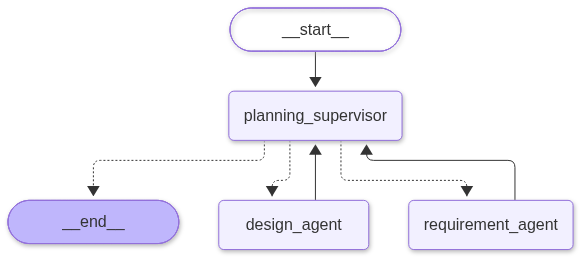

In [48]:
planning_builder = StateGraph(PlanningState)
planning_builder.add_node("planning_supervisor", planning_supervisor)
planning_builder.add_node("requirement_agent", requirement_agent)
planning_builder.add_node("design_agent", design_agent)
planning_builder.add_edge(START, "planning_supervisor")
planning_builder.add_edge("requirement_agent", "planning_supervisor")
planning_builder.add_edge("design_agent", "planning_supervisor")
planning_graph = planning_builder.compile()
planning_graph

In [49]:
import ast # 문자열로 만들어진 파이썬 코드를 분석해주는 모듈

In [50]:
# Development Team 코드 작성과 5개 항목 검토
def development_supervisor(s: DevelopmentState) -> Command[Literal["coding_agent", "review_agent", "__end__"]]:
    if s.get("reviewed", False):
        return Command(goto=END)
    if not s.get("code"):
        return Command(goto="coding_agent")
    if s.get("review") and not s.get("approved", False):
        return Command(goto="coding_agent")
    return Command(goto="review_agent")


'''
```
    python

def a():
    return a
```
'''

# 위에 있는 주석처럼 `을 지우려고 만듦
def strip_code_fences(text: str) -> str:
    value = text.strip()
    if value.startswith("```"):
        value = value.split("\n", 1)[-1] if "\n" in value else ""
        if value.rstrip().endswith("```"):
            value = value.rstrip()[:-3].rstrip()
    return value


def coding_agent(s: DevelopmentState) -> dict:
    previous = s.get("code", "")
    feedback = s.get("review", "")
    prompt = (
        f"사용자 요청:\n{s['request']}\n\n요구사항:\n{s['requirements']}\n\n"
        f"설계:\n{s['design']}\n\n이전 코드:\n{previous}\n\n"
        f"이전 검토 의견:\n{feedback}\n"
    )
    generated = strip_code_fences(ask(
        "당신은 Python개발자입니다. Python 표준 라이브러리만 사용하고, "
        "설계의 모든 기능을 구현한 완전한 Python 소스 코드만 출력하세요, "
        "사용자 요청에 명시된 필수 기능을 빠짐없이 구현하세요. "
        "입력 오류, 빈 데이터, 동점 처리 정책을 명확히 구현하세요. "
        "input()을 호출하거나 모듈 import 시 자동 실행되는 코드를 만들지 마세요. "
        "이전 코드와 검토 의견이 있다면 문제를 수정하세요. ", prompt
    ))

    if not generated:
        raise ValueError("생성된 코드가 비어 있습니다.")

    return {
        "code": generated,
        "review": "",
        "approved": False,
        "reviewed": False,
        "revision_count": s.get("revision_count", 0) + (1 if previous else 0)
    }

def review_agent(s: DevelopmentState) -> dict:
    try:
        ast.parse(s["code"])
    except SyntaxError as exc:  # 몇 번째 줄에서 에러가 났는지 확인 가능
        return {"approved": False, "reviewed": True, "review": f"문법 검사 실패: {exc.msg} (line {exc.lineno})"}

    result = get_review_llm().invoke([
        ("system",
        "당신은 엄격한 Python 코드 리뷰어입니다. 다음 다섯 항목을 각각 판단하세요: "
        "(1) 필수 기능 구현 (2) Python 문법 (3) 함수 분리 (4) 예외 처리 (5) 코드 가독성. "
        "모든 항목이 참일 때만 승입니다. "
        "문제점과 수정 방법을 feedback에 구체적으로 작성하세요. "
        "코드를 실제 실행하지 않았으므로 실행 성공을 보증하지 마세요."),
        ("human", f"사용자 요청:\n{s['request']}\n\n요구사항:\n{s['requirements']}\n\n"
        f"설계:\n{s['design']}\n\n코드:\n{s['code']}")
    ])

    checks = {
        "필수 기능": result.features_ok, "문법": result.syntax_ok, "함수 분리": result.functions_ok, "예외 처리": result.exceptions_ok, "가독성": result.readability_ok
    }
    checklist = "\n".join(f"- {name}: {'통과' if ok else "실패"}" for name, ok in checks.items())
    return {"approved": result.approved, "reviewed": True, "review": f"{checklist}\n\n검토 의견:\n{result.feedback}\n\n(실제 실행 검증은 수행하지 않음)"}

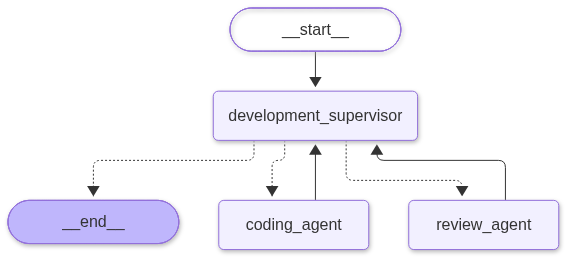

In [51]:
development_builder = StateGraph(DevelopmentState)
development_builder.add_node("development_supervisor", development_supervisor)
development_builder.add_node("coding_agent", coding_agent)
development_builder.add_node("review_agent", review_agent)
development_builder.add_edge(START, "development_supervisor")
development_builder.add_edge("coding_agent", "development_supervisor")
development_builder.add_edge("review_agent", "development_supervisor")
development_graph = development_builder.compile()
development_graph

In [ ]:
def top_supervisor(s: ProjectState) -> Command[Literal["planning_team", "development_team", "save_outputs"]]:
    if not s.get("requirements") or not s.get("design"):
        return Command(goto="planning_team")
    if not s.get("code") or not s.get("reviewed", False):
        return Command(goto="development_team")
    if s.get("approved", False):
        return Command(goto="save_outputs")
    if s.get("revision_count", 0) < MAX_REVISIONS:
        return Command(goto="development_team")
    return Command(goto="save_outputs")

def run_planning(s: ProjectState) -> dict:
    child_input: PlanningState = {"request": s["request"]}
    result = planning_graph.invoke(child_input, config={"recursion_limit": 20})
    return {"requirements": result["requirements"], "design": result["design"]}

def run_development(s: ProjectState) -> dict:
    child_input: DevelopmentState = {
        "request": s["request"], "requirements": s['requirements'],
        "design": s["design"], "code": s.get("code", ""),
        "review": s.get("review", ""), "approved": s.get("approved", False),
        "reviewed": False,
        "revision_count": s.get("revision_count", 0)
    }
    result = development_graph.invoke(child_input, config={"recursion_limit": 20})
    return {key: result[key] for key in("code", "review", "approved", "reviewed", "revision_count")}

def save_outputs(s: ProjectState) -> dict:
    folder = Path("output")
    folder.mkdir(parents = True, exist_ok=True)
    status = "approved" if s.get("approved", False) else "rejected_max_revisions"
    (folder / "requirments.md").write_text(s["requirements"], encoding = "utf-8")
    (folder / "design.md").write_text(s["design"], encoding="utf-8")
    (folder / "generated_program.py").write_text(s.get("code", ""), encoding="utf-8")
    (folder / "review.md").write_text(
        f"# 검토 상태: {status}\n\n수정 횟수: {s.get("revision_count", 0)}\n\n"
        f"{s.get("review", "")}\n", encoding="utf-8"
    )
    return {"saved_path": str(folder.resolve()), "status": status}


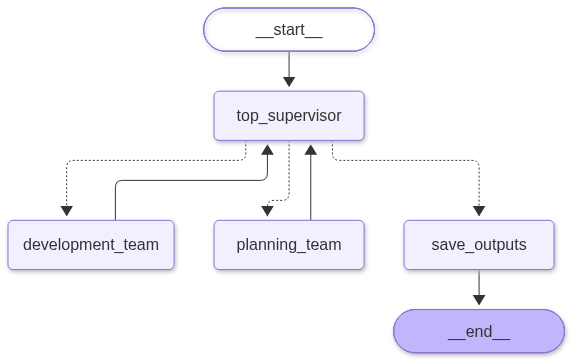

In [53]:
top_builder = StateGraph(ProjectState)
top_builder.add_node("top_supervisor", top_supervisor)
top_builder.add_node("planning_team", run_planning)
top_builder.add_node("development_team", run_development)
top_builder.add_node("save_outputs", save_outputs)
top_builder.add_edge(START, "top_supervisor")
top_builder.add_edge("planning_team", "top_supervisor")
top_builder.add_edge("development_team", "top_supervisor")
top_builder.add_edge("save_outputs", END)
graph = top_builder.compile()
graph

In [54]:
USER_REQUEST = ("학생 성적 관리 프로그램을 만들어줘. 학생 이름과 점수를 등록할 수 있고 전체 학생 목록 조회, 평균 점수 계산, 최고 점수 학생 조회 기능이 필요해")

result = graph.invoke({"request": USER_REQUEST, "revision_count": 0}, config={"recursion_limit":40})

In [55]:
print("최종 상태: ", result.get("status"))
print("승인 여부: ", result.get("approved"))
print("수정 횟수: ", result.get("revision_count"))
print("저장 경로: ", result.get("saved_path"))
print("검토 의견: ", result.get("review"))

최종 상태:  approved
승인 여부:  True
수정 횟수:  0
저장 경로:  C:\VSGit\14_Agent\output
검토 의견:  - 필수 기능: 통과
- 문법: 통과
- 함수 분리: 통과
- 예외 처리: 통과
- 가독성: 통과

검토 의견:
필수 기능인 학생 등록, 전체 목록 조회, 평균 계산, 최고 점수 동점자 전체 조회가 모두 구현되어 있습니다. 이름 양끝 공백 제거, 0~100점 범위 검증, 중복 이름 방지, 빈 성적부 처리도 요구사항에 맞습니다. Python 문법상 문제는 확인되지 않으며, NamedTuple을 사용해 불변 성적부를 반환하는 구조도 적절합니다. 기능별 함수와 내부 검증 함수가 분리되어 있고, TypeError와 ValueError 및 EmptyGradeBookError를 상황별로 구분한 점도 적절합니다. 코드의 함수명, 타입 힌트, docstring, 오류 메시지가 명확하여 가독성도 양호합니다. 다만 코드를 실제 실행하지 않았으므로 실행 성공을 보증할 수는 없습니다. 추가 개선이 필요하다면 `_validate_gradebook`에서 GradeBook 내부의 students 요소가 Student인지까지 검증하거나, 공개 API 사용 예시와 단위 테스트를 별도로 추가할 수 있습니다.

(실제 실행 검증은 수행하지 않음)


### 추가 개선 과제
- 팀별 상태 이력 및 LLM호출 비용 추적
- 검토 실패 시 사람이 승인하거나 중단할 수 있는 Human in the loop 단계 추가


# 내가함

In [ ]:
# 기존 프로젝트 상태에 팀별 실행 이력 필드 추가
class TrackedState(ProjectState, total=False):
    history: list[dict]

In [57]:
# LLM의 토큰 사용량을 집계하는 도구를 가져오는 코드
from langchain_core.callbacks import get_usage_metadata_callback

In [ ]:
# 이건 gpt 공식문서에 있음
INPUT_PRICE = 0.2
OUTPUT_PRICE = 1.2

# state는 현재 상태, team은 팀 이름, run은 실행할 팀 함수
def run_team(state, team, run):
    # with는 컨텍스트 매니저로
    # 파일 열기, DB 연결, 락(lock) 획득 같은 작업을 안전하게 시작하고 자동으로 정리해주는 문법
    with get_usage_metadata_callback() as usage:
        changes = run(state)

    # 팀 실행 결과를 이력에 남길 문구로 정리
    if team == "기획팀":
        outcome = "설계 완료"
    else:
        if changes["approved"]:
            outcome = "검토 통과"
        else:
            outcome = "검토 실패"

    # 모델별 사용량 딕셔너리에서 사용량 정보들만 꺼냄
    records = usage.usage_metadata.values()

    # 사용량이 제공되지 않거나 단가가 없으면 None으로 유지
    tokens_in = None
    tokens_out = None
    cost = None

    if records:
        tokens_in = sum(record["input_tokens"] for record in records)
        tokens_out = sum(record["output_tokens"] for record in records)

        # 두 단가가 설정되어 있으면 예상 비용 계산
        # 현재 계산은 모든 입력 토큰에 일반 입력 단가를 적용
        if INPUT_PRICE is not None and OUTPUT_PRICE is not None:
            cost = (
                tokens_in * INPUT_PRICE + tokens_out * OUTPUT_PRICE
            ) / 1000000

    # 이번 팀 실행 한 번의 기록
    entry = {
        "team": team,
        "outcome": outcome,
        "input": tokens_in,
        "output": tokens_out,
        "cost": cost,
    }

    # 기존 이력이 없으면 빈 리스트에서 시작하고 새 기록을 추가
    changes["history"] = state.get("history", []) + [entry]

    # 팀 실행 결과와 이력을 그래프 상태에 반영하도록 반환
    return changes

In [ ]:
# 반환 타입에 이동 가능한 노드를 표시해 그래프 시각화에 사용
def supervisor(state) -> Command[Literal["planning_team", "development_team", "save_outputs", "__end__"]]:
    # 자동 검토를 수행했고 승인되지 않은 경우 사람이 판단
    if state.get("reviewed") and not state.get("approved"):
        print("자동 검토 실패")
        print(state["review"])

        choices = ["승인", "중단"]

        # 수정 가능 횟수가 남아 있을 때만 수정 선택지를 추가
        if state.get("revision_count", 0) < MAX_REVISIONS:
            choices.append("수정")

        # 허용된 선택지를 입력할 때까지 반복
        while True:
            # strip()으로 입력값 앞뒤의 공백 제거
            choice = input(f"{choices} 중 선택").strip()

            if choice in choices:
                break

            print("표시된 선택지 중 하나를 입력하세요.")

        if choice == "승인":
            # 사람 승인 상태를 기록하고 결과 저장 단계로 이동
            return Command(update={"status": "human_approved"}, goto="save_outputs")
        elif choice == "중단":
            # 아래 그래프 생성할 필요가 없음
            # 이유: goto=END로 바로 감
            return Command(update={"status": "human_stopped"}, goto=END)

        # 남은 선택인 수정은 개발팀으로 전달
        return Command(goto="development_team")
    
    # 검토 실패 외의 상황은 기존 감독자에게 작업 순서 판단을 맡김
    return top_supervisor(state) 

In [ ]:
# 수업할 때 사용했던 함수 그대로 사용
# status만 변경
def save_outputs(s: ProjectState) -> dict:
    folder = Path("output")
    folder.mkdir(parents = True, exist_ok=True)

    # 사람이 결정한 status가 있으면 사용
    # status가 없으면 자동 검토 승인 여부로 최종 상태 결정
    status = s.get(
        "status",
        "approved" if s.get("approved", False) else "rejected_max_revisions"
    )

    (folder / "requirments.md").write_text(s["requirements"], encoding = "utf-8")
    (folder / "design.md").write_text(s["design"], encoding="utf-8")
    (folder / "generated_program.py").write_text(s.get("code", ""), encoding="utf-8")
    (folder / "review.md").write_text(
        f"# 검토 상태: {status}\n\n수정 횟수: {s.get("revision_count", 0)}\n\n"
        f"{s.get("review", "")}\n", encoding="utf-8"
    )
    return {"saved_path": str(folder.resolve()), "status": status}

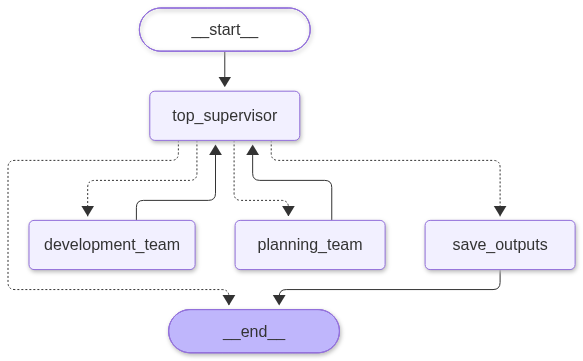

In [76]:
top_builder = StateGraph(TrackedState)
top_builder.add_node("top_supervisor", supervisor)
top_builder.add_node("planning_team", lambda state: run_team(state, "기획팀", run_planning))
top_builder.add_node("development_team", lambda state: run_team(state,"개발팀", run_development))
top_builder.add_node("save_outputs", save_outputs)



top_builder.add_edge(START, "top_supervisor")
top_builder.add_edge("planning_team", "top_supervisor")
top_builder.add_edge("development_team", "top_supervisor")
top_builder.add_edge("save_outputs", END)

graph = top_builder.compile()
graph

In [77]:
result = graph.invoke({"request": USER_REQUEST, "revision_count": 0}, config={"recursion_limit":40})
result

{'request': '학생 성적 관리 프로그램을 만들어줘. 학생 이름과 점수를 등록할 수 있고 전체 학생 목록 조회, 평균 점수 계산, 최고 점수 학생 조회 기능이 필요해',
 'requirements': '# 프로젝트 목적\n\n학생의 이름과 점수를 등록하고, 등록된 학생 성적을 조회·분석할 수 있는 성적 관리 프로그램을 개발한다.\n\n# 필수 기능 목록\n\n1. **학생 성적 등록**\n   - 학생 이름과 점수를 입력받아 등록한다.\n   - 학생별 이름과 점수를 저장한다.\n\n2. **전체 학생 목록 조회**\n   - 등록된 모든 학생의 이름과 점수를 조회한다.\n\n3. **평균 점수 계산**\n   - 등록된 전체 학생의 평균 점수를 계산한다.\n   - 등록된 학생이 없을 경우 평균을 계산할 수 없음을 안내한다.\n\n4. **최고 점수 학생 조회**\n   - 가장 높은 점수를 받은 학생의 이름과 점수를 조회한다.\n   - 등록된 학생이 없을 경우 최고 점수 학생이 없음을 안내한다.\n\n# 입력과 출력\n\n## 입력\n\n- 학생 이름\n- 학생 점수\n- 기능 선택값\n  - 학생 성적 등록\n  - 전체 학생 목록 조회\n  - 평균 점수 계산\n  - 최고 점수 학생 조회\n\n## 출력\n\n- 성적 등록 결과\n- 전체 학생 목록\n- 전체 학생 평균 점수\n- 최고 점수 학생의 이름과 점수\n- 입력 오류 또는 조회 결과가 없는 경우의 안내 메시지\n\n## 데이터 예시\n\n```text\n학생 이름: 김민수\n점수: 85\n```\n\n등록된 학생 목록 출력 예시:\n\n```text\n김민수: 85점\n이서연: 92점\n```\n\n평균 점수 출력 예시:\n\n```text\n평균 점수: 88.5점\n```\n\n최고 점수 학생 출력 예시:\n\n```text\n최고 점수 학생: 이서연, 92점\n```\n\n# 예외 처리 요구사항\n\n- 학생 이름이 입력되지 않은 경우 등록하지 않고 오류 메시지를 출력한다.\n-

In [78]:
print("최종 상태:", result["status"])

for entry in result["history"]:
    print(entry)

최종 상태: approved
{'team': '기획팀', 'outcome': '설계 완료', 'input': 795, 'output': 4558, 'cost': 0.005628599999999999}
{'team': '개발팀', 'outcome': '검토 통과', 'input': 9807, 'output': 2346, 'cost': 0.004776600000000001}
